# Comparison to Clinical Outcomes

In [1]:
import os
import sys
import math
import pickle
import numpy as np
import pandas as pd
import scipy as sc
from scipy.stats import linregress, pearsonr, spearmanr, kendalltau
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (calc_delta_benefit, calc_critical_treatment_threshold, LoadPatientData, predict_drug_benefit,
                     predict_ct_ttp, predict_atx_ttp, predict_at_threshold_ttp, calc_average_overshoot)
from plotUtils import PlotDrug, PlotSimulation, convert_to_rgb_grayscale
from odeModels import LotkaVolterraModel

In [2]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_30636/884701199.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([''] + list(colors.keys()));


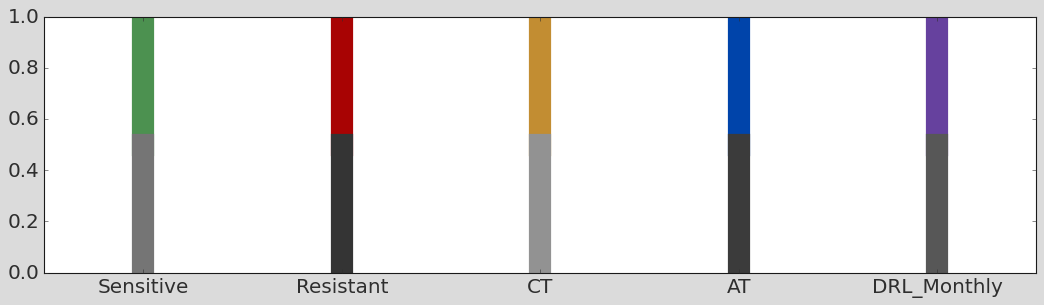

In [3]:
# Defaults for plotting
colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

fig, ax = plt.subplots(1, 1, figsize=(16, 4))
for i, col in enumerate(colors.values()):
    plt.axvline(i+1, 0.5, 1, color = col, linewidth=20)
    plt.axvline(i+1, 0, 0.5, color = convert_to_rgb_grayscale(col), linewidth=20)
plt.xlim(0.5, len(colors.values()) + 0.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().set_xticklabels([''] + list(colors.keys()));

In [4]:
file_path = os.path.dirname(os.path.abspath("__file__"))

out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Prog_fits")

In [5]:
def Plot_method(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_color = 'k', colors = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    linestyles = ['-', '--', '--']
    for i, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df['Time'], df[var], linewidth=linewidth, linestyle=linestyles[i], color=colors[var], **kwargs)

    PlotDrug(df, ax, drug_color, plotDrugAsBar = True, currDrugBarPosition = 1.25)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)

## Patient Datasets

In [6]:
# Load the data
df = pd.read_csv("patient_fits/full_history_params.csv")
trunc_df = pd.read_csv("patient_fits/first_cycle_params.csv")

patientIds = pd.merge(df[['PatientId']], trunc_df[['PatientId']], 
                      on='PatientId')['PatientId'].unique()

n = len(df['PatientId'].unique())
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd',]

## TTP Prediction

In [7]:
def calc_threshold_benefit(ave_n, **kwargs):
    params = kwargs
    return calc_delta_benefit(kappa=(ave_n / params['K']), **params)

def predict_at50_ttp_simp(**kwargs):
    # Simplified version that doesn't account for overshooting
    params = kwargs
    n_crit = params['n0']/2
    ave_n = (n_crit +  params['n0']) / 2
    benefit = calc_threshold_benefit(ave_n, **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

def predict_at_threshold_ttp_simp(n_crit, **kwargs):
    # Simplified version that doesn't account for overshooting
    params = kwargs
    benefit = calc_delta_benefit(kappa=n_crit / params['K'], **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

In [8]:
data_path = "../patients/Bruchovsky_et_al/Complete_data"
def get_ttp(patientId, **kwargs):
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['PSA'] < 1.2 * dataDf['PSA'].iloc[0]]
    return dataDf['Time'].iloc[-1]

print(get_ttp(patientIds[0]))

839


In [9]:
def get_N_star(patientId, **kwargs):
    ttp = get_ttp(patientId, **kwargs)
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['Time'] <= ttp]

    N_star = dataDf['PSA'].mean()
    interval = dataDf['Time'].diff().mean()
    overshoot = calc_average_overshoot(int(interval), N_star, **kwargs)
    return N_star + overshoot

param_set = trunc_df.loc[trunc_df.PatientId == patientIds[2]].iloc[0].to_dict()
print(get_N_star(patientIds[2], **param_set))

0.7199379859564563


In [10]:
def fraction_time_below_threshold(dataDf, threshold, time_col="Time", value_col="PSA"):
    tmp = (
        dataDf[[time_col, value_col]]
        .dropna()
        .sort_values(time_col)
        .groupby(time_col, as_index=False)[value_col].mean()
    )

    if len(tmp) < 2:
        return np.nan

    t = tmp[time_col].to_numpy(dtype=float)
    y = tmp[value_col].to_numpy(dtype=float)

    dt = np.diff(t)
    valid = dt > 0
    if not np.any(valid):
        return np.nan

    y0 = y[:-1][valid]
    y1 = y[1:][valid]
    dt = dt[valid]

    all_under = (y0 <= threshold) & (y1 <= threshold)
    all_over = (y0 > threshold) & (y1 > threshold)
    crossing = ~(all_under | all_over)

    under_time = np.sum(dt[all_under])

    if np.any(crossing):
        alpha = (threshold - y0[crossing]) / (y1[crossing] - y0[crossing])
        alpha = np.clip(alpha, 0.0, 1.0)

        # If segment starts below threshold, time below is alpha * dt.
        # If segment starts above threshold, time below is (1 - alpha) * dt.
        crossing_under_time = np.where(
            y0[crossing] <= threshold,
            alpha * dt[crossing],
            (1.0 - alpha) * dt[crossing],
        )
        under_time += np.sum(crossing_under_time)

    total_time = np.sum(dt)
    return under_time / total_time

In [11]:
def predict_clinical_ttp(patientId, **kwargs):
    param_set = kwargs

    ttp = get_ttp(patientId, **kwargs)
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    dataDf = dataDf[dataDf['Time'] <= ttp]

    threshold = 2.5 / dataDf['PSA_raw'].iloc[0]  # 2.5 ng/mL normalized by initial PSA
    N_star = dataDf[dataDf['PSA']>=threshold]['PSA'].mean()
    at_ttp = predict_at_threshold_ttp_simp(param_set['n0'] * N_star, **param_set)
    ct_ttp = predict_ct_ttp(**param_set)


    fraction_under_threshold = fraction_time_below_threshold(dataDf, threshold)
    weighted_increment = (1 - fraction_under_threshold) * (at_ttp - ct_ttp)
    return ct_ttp + weighted_increment


param_set = trunc_df.loc[trunc_df.PatientId == patientIds[2]].iloc[0].to_dict()
print(predict_clinical_ttp(patientIds[2], **param_set))

1344.2809839799652


In [12]:
# Generate a table with patient id, predicted AT TTP
TTP_data = []
param_sets = [trunc_df]

for patientId in tqdm(patientIds):
    param_set = trunc_df.loc[trunc_df.PatientId == patientId].iloc[0].to_dict()
    
    ct_perfect_preds = int(predict_ct_ttp(**param_set))
    at50_perfect_preds = int(predict_at50_ttp_simp(**param_set))
    atx_overshoot_preds = int(predict_atx_ttp(30, **param_set))
    ncrit_perfect_preds = int(predict_at_threshold_ttp_simp(param_set['n0'], **param_set))
    ncrit_overshoot_preds = int(predict_at_threshold_ttp(30, **param_set)) 
    match_preds = int(predict_at_threshold_ttp_simp(param_set['n0'] * get_N_star(patientId, **param_set), **param_set))
    clinical_preds = int(predict_clinical_ttp(patientId, **param_set))
    clinical_ttps = int(get_ttp(patientId))
    
    
    TTP_data.append([patientId, ct_perfect_preds, at50_perfect_preds, atx_overshoot_preds, 
                     ncrit_perfect_preds, ncrit_overshoot_preds, match_preds, clinical_preds, clinical_ttps])

at_ttp_df = pd.DataFrame(TTP_data, columns=['PatientId', 'CT_Perfect', 'AT50_Perfect', 'ATX_Overshoot',
                                                   'AT_NCrit_Perfect', 'AT_NCRIT_Overshoot', 'Match_Preds', 'Clinical_Preds', 'Clinical_TTP'])
print(at_ttp_df)

100%|██████████| 5/5 [00:00<00:00, 132.82it/s]

100%|██████████| 5/5 [00:00<00:00, 132.82it/s]

   PatientId  CT_Perfect  AT50_Perfect  ATX_Overshoot  AT_NCrit_Perfect  \
0         12         542           797            862               944   
1         20         905          1798           2205              2681   
2         25         816          1505           1779              2095   
3         78         996          2134           2727              3447   
4         85         702          1174           1331              1514   

   AT_NCRIT_Overshoot  Match_Preds  Clinical_Preds  Clinical_TTP  
0                 805          664             637           839  
1                2805         1326            1220          1451  
2                2023         1456            1344          1327  
3                4045         1377            1277          1248  
4                1362         1009             924           665  


(0.0, 1596.1000000000001)

(0.0, 1596.1000000000001)

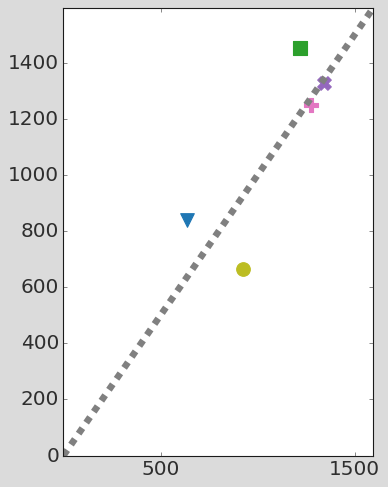

In [13]:
scale_extension = 1.1

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(5, 7))
for i, patientId in enumerate(patientIds):
    ax.scatter(at_ttp_df.loc[at_ttp_df['PatientId'] == patientId, 'Clinical_Preds'],
               at_ttp_df.loc[at_ttp_df['PatientId'] == patientId, 'Clinical_TTP'],
               color=cols[i], s=150, marker=markers[i],
               label=f'Patient {patientId}')

max_time = max(at_ttp_df['Clinical_Preds'].max(), at_ttp_df['Clinical_TTP'].max())
ax.plot([0, max_time * scale_extension], [0, max_time*scale_extension], 
        linestyle='--', linewidth=6, color='gray', label='Guide Line')

ax.set_xticks(ax.get_xticks()[::2])
# ax.set_xlabel('True Doubling Time'); ax.set_ylabel('Predicted Doubling Time')
ax.set_xlim(0, max_time*scale_extension); ax.set_ylim(0, max_time*scale_extension)
# ax.legend(loc=2)
# plt.savefig("figures/ttp_comparison_output.pdf", dpi=300, bbox_inches='tight')

In [14]:
def regression_plot(x_vals, y_vals, ax, xlabel, ylabel, title, use_percent=True, cols=None, markers=None):
    if cols is None: cols = ['k'] * len(x_vals)
    if markers is None: markers = ['o'] * len(x_vals)
    for n, (x, y) in enumerate(zip(x_vals, y_vals)):
        ax.scatter(x, y, color=cols[n], marker=markers[n], s=100)
    
    slope, intercept = np.polyfit(x_vals, y_vals, 1)
    line_sim = slope * np.array(x_vals) + intercept
    ax.plot(sorted(x_vals), sorted(line_sim), color=colors['CT'], linestyle='--')
    
    r2_sim = np.corrcoef(x_vals, y_vals)[0, 1] ** 2
    ax.annotate(f"$R^{2} = {r2_sim:.2f}$", xy=(0.05, 0.85), xycoords='axes fraction', fontsize=22)
    ax.tick_params(top=False, right=False);
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.set_xticks(ax.get_xticks()[::2]); ax.set_yticks(ax.get_yticks()[::2]); 
    if min(y_vals) > 0:
        ax.set_ylim(bottom=0)

    if use_percent:
        ax.set_yticklabels([f"{int(x*100)}" for x in ax.get_yticks()])
        ax.set_xticklabels([f"{int(x*100)}" for x in ax.get_xticks()])

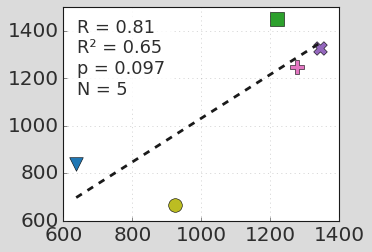

In [117]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(5, 3.5))

x_vals = at_ttp_df['Clinical_Preds'].to_numpy(dtype=float)
y_vals = at_ttp_df['Clinical_TTP'].to_numpy(dtype=float)

# Plot points colored by patient
for i, patientId in enumerate(patientIds):
    ax.scatter(
        x_vals[i], y_vals[i],
        color=cols[i], marker=markers[i], s=150,
        label=f'Patient {patientId}',
        edgecolor='black', linewidth=0.5
    )

# Linear regression
if len(x_vals) >= 2 and np.std(x_vals) > 0:
    fit = linregress(x_vals, y_vals)
    xline = np.linspace(np.nanmin(x_vals), np.nanmax(x_vals), 100)
    yline = fit.slope * xline + fit.intercept
    ax.plot(xline, yline, color='k', linestyle='--', linewidth=2.5, label='Linear fit')

    r, p = pearsonr(x_vals, y_vals)
    ax.annotate(
        f"R = {r:.2f}\nR² = {r**2:.2f}\np = {p:.3f}\nN = {len(x_vals)}",
        xy=(0.05, 0.95), xycoords='axes fraction',
        ha='left', va='top', fontsize=16,
        bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='none', alpha=0.8)
    )

# ax.set_xlabel('Clinical_Preds (days)')
# ax.set_ylabel('Clinical_TTP (days)')
# ax.set_title('Clinical Predictions vs Clinical Outcomes')
ax.set_xticks(ax.get_xticks()[::2]); 
ax.set_yticks(ax.get_yticks()[::2]); 
ax.tick_params(top=False, right=False)
ax.grid(alpha=0.3)
# ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig("figures/clinical_ttp_comparison_output.pdf", dpi=300, bbox_inches='tight')
plt.show()

Both the `Match_Preds` approach (computing based on the mean N(t)) and the `Clinical_Preds` approach (which also accounts for the amount of time spent below the reporting threshold for PSA) give very similar results (R^2 =0.64 or 0.65).

In [16]:

# Linear regression
slope, intercept, r_value, p_value_linear, std_err = linregress(
    at_ttp_df['Clinical_Preds'], at_ttp_df['Clinical_TTP']
)

# slope uncertainty = standard error from linregress
print("Linear Regression:")
print(f"  R² = {r_value**2:.4f}")
print(f"  p-value = {p_value_linear:.4f}")
print(f"  slope = {slope:.4f} ± {std_err:.4f}")
print(f"  intercept = {intercept:.4f}")

# Spearman's rank correlation
spearman_rho, p_value_spearman = spearmanr(at_ttp_df['Clinical_Preds'], at_ttp_df['Clinical_TTP'])
print(f"\nSpearman's Rank Correlation:")
print(f"  rho = {spearman_rho:.4f}")
print(f"  p-value = {p_value_spearman:.4f}")

# Kendall's tau
tau, p_value_kendall = kendalltau(at_ttp_df['Clinical_Preds'], at_ttp_df['Clinical_TTP'])
print(f"\nKendall's Tau:")
print(f"  tau = {tau:.4f}")
print(f"  p-value = {p_value_kendall:.4f}")

Linear Regression:
  R² = 0.6540
  p-value = 0.0975
  slope = 0.9226 ± 0.3874
  intercept = 109.2405

Spearman's Rank Correlation:
  rho = 0.6000
  p-value = 0.2848

Kendall's Tau:
  tau = 0.4000
  p-value = 0.4833


## Drug Benefit

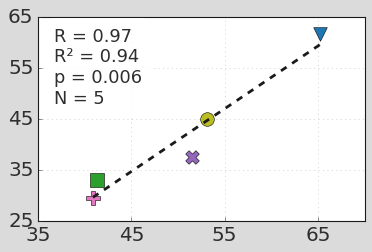

Fraction on treatment: [np.float64(0.6519666269368296), np.float64(0.4135079255685734), np.float64(0.5145287030474841), np.float64(0.4088482074752098), np.float64(0.5313807531380753)]
eMDD predictions: [np.float64(0.6153257616536584), np.float64(0.3301540399608086), np.float64(0.3740692365367511), np.float64(0.29482447024919356), np.float64(0.4501672729055054)]


In [115]:
# Compute eMDD predictions for each patient
eMDD_preds = []
for patientId in patientIds:
    param_set = trunc_df.loc[trunc_df.PatientId == patientId].iloc[0].to_dict()
    emdd = predict_drug_benefit(tau=30, n_crit=0.5 * param_set['n0'], **param_set)
    eMDD_preds.append(emdd)

# Compute fraction of time on treatment for each patient
fraction_on_treatment = []
for patientId in patientIds:
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    
    if "DrugConcentration" in dataDf.columns:
        on_treatment = (dataDf["DrugConcentration"].fillna(0) > 0).astype(int)
        total_time = dataDf['Time'].max() - dataDf['Time'].min()
        
        # Calculate time on treatment using trapezoidal integration
        t = dataDf['Time'].to_numpy(dtype=float)
        dt = np.diff(t)
        on = on_treatment.to_numpy(dtype=float)[:-1]
        time_on = np.sum(on * dt)
        
        frac_on = time_on / total_time if total_time > 0 else np.nan
    else:
        frac_on = np.nan
    
    fraction_on_treatment.append(frac_on)

# Create scatter plot with linear regression
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(5, 3.5))

x_vals = np.array(fraction_on_treatment)
y_vals = np.array(eMDD_preds)

# Plot points colored by patient
for i, patientId in enumerate(patientIds):
    ax.scatter(x_vals[i], y_vals[i], color=cols[i], marker=markers[i], s=150, 
               label=f'Patient {patientId}', edgecolor='black', linewidth=0.5)

# Linear regression
if len(x_vals) >= 2 and np.std(x_vals) > 0:
    fit = linregress(x_vals, y_vals)
    xline = np.linspace(np.nanmin(x_vals), np.nanmax(x_vals), 100)
    yline = fit.slope * xline + fit.intercept
    ax.plot(xline, yline, color='k', linestyle='--', linewidth=2.5, label='Linear fit')
    
    r, p = pearsonr(x_vals, y_vals)
    ax.annotate(f"R = {r:.2f}\nR² = {r**2:.2f}\np = {p:.3f}\nN = {len(x_vals)}", 
                xy=(0.05, 0.95), xycoords='axes fraction',
                ha='left', va='top', fontsize=16,
                bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='none', alpha=0.8))

# ax.set_xlabel('Fraction of Time on Treatment')
# ax.set_ylabel('eMDD Prediction (days)')
# ax.set_title('eMDD vs Treatment Duration')
ax.tick_params(top=False, right=False)
ax.grid(alpha=0.3)
ax.set_xticks(ax.get_xticks()[::2]); ax.set_xticklabels([f"{int(x*100)}" for x in ax.get_xticks()])
ax.set_yticks(ax.get_yticks()[::2]); ax.set_yticklabels([f"{int(y*100)}" for y in ax.get_yticks()])
# ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig("figures/emdd_vs_treatment_duration.pdf", dpi=300, bbox_inches='tight')
plt.show()

print(f"Fraction on treatment: {fraction_on_treatment}")
print(f"eMDD predictions: {eMDD_preds}")


## Comparison to Existing Clinical Metrics

Benchmarking against simple clinical/phenomenologic baselines (PSA doubling time, PSA nadir, time to nadir, off-treatment PSA regrowth slope, PSA velocity, and baseline tumor burden)

In [105]:
def get_series(patientId):
    dataDf = LoadPatientData(patientId, data_path)
    dataDf = dataDf[dataDf['PSA'].isna() == False]
    return(dataDf.head(10))


print(get_series(patientIds[2]))

    PatientId       Date    CPA  LEU       PSA  Testosterone  CycleId  \
0          25 1995-09-15  200.0  NaN  1.000000          16.0        1   
4          25 1995-12-07  100.0  7.5  0.050633           1.2        1   
7          25 1996-03-05  100.0  7.5  0.025316           NaN        1   
9          25 1996-04-30  100.0  7.5  0.025316           1.1        1   
10         25 1996-05-28  100.0  NaN  0.025316           NaN        1   
11         25 1996-06-26    NaN  NaN  0.037975           1.1        1   
12         25 1996-07-24    NaN  NaN  0.075949           NaN        1   
13         25 1996-08-21    NaN  NaN  0.278481           8.2        1   
14         25 1996-09-18    NaN  NaN  0.430380          10.7        1   
15         25 1996-10-17    NaN  NaN  0.531646           9.5        1   

    DrugConcentration     8    9  Time  PSA_raw  
0                   1  9388   96     0      7.9  
4                   1  9471  179    83      0.4  
7                   1  9560  268   172      0.

In [18]:
def _pick_psa_column(df):
    if "PSA_raw" in df.columns and df["PSA_raw"].notna().sum() > 0:
        return "PSA_raw"
    return "PSA"

def _safe_linregress(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return np.nan, np.nan, np.nan  # slope, intercept, pvalue
    if np.allclose(x, x[0]) or np.allclose(y, y[0]):
        return np.nan, np.nan, np.nan
    res = linregress(x, y)
    return res.slope, res.intercept, res.pvalue

def get_first_cycle_df(patient_id, data_path):
    df = LoadPatientData(patient_id, data_path).copy()
    df = df.sort_values("Time").reset_index(drop=True)

    # Prefer explicit cycle labels if available
    if "CycleId" in df.columns and df["CycleId"].notna().sum() > 0:
        c1 = df[df["CycleId"] == 1].copy()
        if len(c1) > 0:
            return c1.sort_values("Time").reset_index(drop=True)

    # Fallback: first contiguous treatment episode starting at first timepoint
    # (from first row until first change in DrugConcentration state and back)
    if "DrugConcentration" in df.columns:
        drug = df["DrugConcentration"].fillna(method="ffill").fillna(0.0).to_numpy()
        on = drug > 0
        # Define first cycle as all points until the first return to on after an off period
        seen_off = False
        end_idx = len(df) - 1
        for i in range(1, len(df)):
            if not on[i]:
                seen_off = True
            if seen_off and on[i]:
                end_idx = i - 1
                break
        return df.iloc[: end_idx + 1].copy().reset_index(drop=True)

    return df.copy().reset_index(drop=True)

In [19]:
def compute_first_cycle_metrics(patient_id, data_path):
    c1 = get_first_cycle_df(patient_id, data_path)
    psa_col = _pick_psa_column(c1)

    # Keep only valid rows for metric calculations
    c1v = c1[["Time", psa_col] + ([ "DrugConcentration" ] if "DrugConcentration" in c1.columns else [])].copy()
    c1v = c1v.dropna(subset=["Time", psa_col]).sort_values("Time")
    c1v = c1v.groupby("Time", as_index=False).mean(numeric_only=True)  # handles duplicate times

    out = {
        "PatientId": patient_id,
        "Baseline_Tumor_Burden": np.nan,
        "PSA_Nadir": np.nan,
        "Time_to_Nadir": np.nan,
        "PSA_Velocity_per_day": np.nan,
        "PSA_Velocity_per_month": np.nan,
        "PSA_Doubling_Time_days": np.nan,
        "Regrowth_n_points": 0
    }

    if len(c1v) == 0:
        return out

    # Baseline tumor burden: first observed PSA in first cycle
    t0 = float(c1v["Time"].iloc[0])
    p0 = float(c1v[psa_col].iloc[0])
    out["Baseline_Tumor_Burden"] = p0

    # Nadir and time to nadir
    nadir_idx = int(np.nanargmin(c1v[psa_col].to_numpy(dtype=float)))
    t_nadir = float(c1v["Time"].iloc[nadir_idx])
    p_nadir = float(c1v[psa_col].iloc[nadir_idx])

    out["PSA_Nadir"] = p_nadir
    out["Time_to_Nadir"] = t_nadir - t0

    # Regrowth window: from nadir to cycle end, ideally off-treatment only
    reg = c1v[c1v["Time"] >= t_nadir].copy()

    if "DrugConcentration" in reg.columns:
        off = reg[reg["DrugConcentration"].fillna(0.0) <= 0].copy()
        # If too few off-treatment points, fallback to nadir->end points
        if len(off) >= 2:
            reg = off

    # Need at least 2 points for slopes
    if len(reg) < 2:
        return out

    x = reg["Time"].to_numpy(dtype=float)
    y = reg[psa_col].to_numpy(dtype=float)

    # Raw linear slope: off-treatment regrowth slope and PSA velocity
    slope_lin, intercept_lin, p_lin = _safe_linregress(x, y)
    out["Regrowth_Slope_per_day"] = slope_lin
    out["PSA_Velocity_per_day"] = slope_lin
    out["PSA_Velocity_per_month"] = slope_lin * 30.437 if np.isfinite(slope_lin) else np.nan
    out["Regrowth_n_points"] = len(reg)

    # PSA doubling time from log-linear regression over regrowth PSA
    pos = y > 0
    if np.sum(pos) >= 2:
        slope_log, intercept_log, p_log = _safe_linregress(x[pos], np.log(y[pos]))
        if np.isfinite(slope_log) and slope_log > 0:
            out["PSA_Doubling_Time_days"] = np.log(2.0) / slope_log
        else:
            out["PSA_Doubling_Time_days"] = np.nan  # flat/declining or ill-defined
    else:
        out["PSA_Doubling_Time_days"] = np.nan

    return out

In [20]:
metric_rows = []
for pid in patientIds:
    metric_rows.append(compute_first_cycle_metrics(pid, data_path))

metrics_df = pd.DataFrame(metric_rows).sort_values("PatientId").reset_index(drop=True)
print(metrics_df)

   PatientId  Baseline_Tumor_Burden  PSA_Nadir  Time_to_Nadir  \
0         12                   10.7        0.6          280.0   
1         20                   13.2        0.6          301.0   
2         25                    7.9        0.2          172.0   
3         78                   19.0        0.6          315.0   
4         85                   11.6        1.6          297.0   

   PSA_Velocity_per_day  PSA_Velocity_per_month  PSA_Doubling_Time_days  \
0              0.057694                1.756034               23.857488   
1              0.027315                0.831373               79.502751   
2              0.017755                0.540414              129.738469   
3              0.041937                1.276437              109.363089   
4              0.038081                1.159058               94.432622   

   Regrowth_n_points  Regrowth_Slope_per_day  
0                  4                0.057694  
1                  7                0.027315  
2                

In [21]:
bench_df = pd.merge(metrics_df, at_ttp_df, on="PatientId", how="inner")
print(bench_df.shape)
print(bench_df.head())

(5, 17)
   PatientId  Baseline_Tumor_Burden  PSA_Nadir  Time_to_Nadir  \
0         12                   10.7        0.6          280.0   
1         20                   13.2        0.6          301.0   
2         25                    7.9        0.2          172.0   
3         78                   19.0        0.6          315.0   
4         85                   11.6        1.6          297.0   

   PSA_Velocity_per_day  PSA_Velocity_per_month  PSA_Doubling_Time_days  \
0              0.057694                1.756034               23.857488   
1              0.027315                0.831373               79.502751   
2              0.017755                0.540414              129.738469   
3              0.041937                1.276437              109.363089   
4              0.038081                1.159058               94.432622   

   Regrowth_n_points  Regrowth_Slope_per_day  CT_Perfect  AT50_Perfect  \
0                  4                0.057694         542           797   
1 

In [22]:
def correlation_report(df, metric_cols, target_cols):
    rows = []
    for m in metric_cols:
        for t in target_cols:
            sub = df[[m, t]].dropna()
            n = len(sub)
            if n < 3:
                rows.append({
                    "Metric": m, "Target": t, "N": n,
                    "Pearson_r": np.nan, "Pearson_R2": np.nan, "Pearson_p": np.nan,
                    "Spearman_rho": np.nan, "Spearman_p": np.nan,
                    "Kendall_tau": np.nan, "Kendall_p": np.nan
                })
                continue

            x = sub[m].to_numpy(dtype=float)
            y = sub[t].to_numpy(dtype=float)

            pr, pp = pearsonr(x, y)
            sr, sp = spearmanr(x, y)
            kt, kp = kendalltau(x, y)

            rows.append({
                "Metric": m, "Target": t, "N": n,
                "Pearson_r": pr, "Pearson_R2": pr**2, "Pearson_p": pp,
                "Spearman_rho": sr, "Spearman_p": sp,
                "Kendall_tau": kt, "Kendall_p": kp
            })

    return pd.DataFrame(rows)

In [23]:
metric_cols = [
    "Clinical_Preds",
    "PSA_Doubling_Time_days",
    "PSA_Nadir",
    "Time_to_Nadir",
    "PSA_Velocity_per_day",
    "Baseline_Tumor_Burden"
]

# Choose targets you want to benchmark against
target_cols = ["Clinical_TTP"]  # add others if desired, e.g. "Clinical_Preds", "Match_Preds"

corr_df = correlation_report(bench_df, metric_cols, target_cols)
print(corr_df.sort_values(["Target", "Metric"]).to_string(index=False))

                Metric       Target  N  Pearson_r  Pearson_R2  Pearson_p  Spearman_rho  Spearman_p  Kendall_tau  Kendall_p
 Baseline_Tumor_Burden Clinical_TTP  5   0.184660    0.034099   0.766227       0.10000    0.872889     0.000000   1.000000
        Clinical_Preds Clinical_TTP  5   0.808710    0.654012   0.097499       0.60000    0.284757     0.400000   0.483333
PSA_Doubling_Time_days Clinical_TTP  5   0.437369    0.191292   0.461426       0.20000    0.747060     0.200000   0.816667
             PSA_Nadir Clinical_TTP  5  -0.753420    0.567642   0.141422      -0.67082    0.215170    -0.597614   0.165518
  PSA_Velocity_per_day Clinical_TTP  5  -0.632155    0.399620   0.252512      -0.60000    0.284757    -0.400000   0.483333
         Time_to_Nadir Clinical_TTP  5  -0.245814    0.060424   0.690202       0.10000    0.872889     0.000000   1.000000


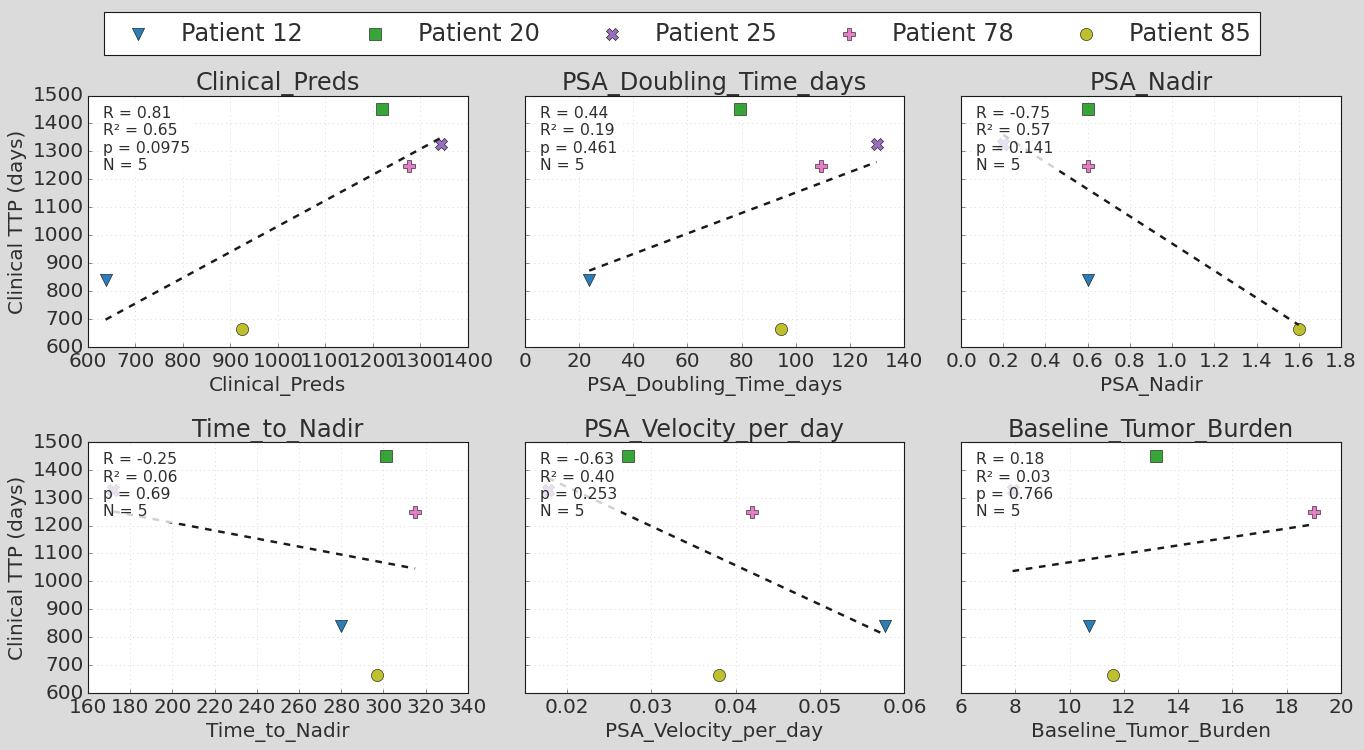

In [24]:
def plot_metrics_vs_ttp_by_patient_ordered(
    df,
    metric_cols,
    patient_ids,
    cols,
    markers,
    target_col="Clinical_TTP",
    patient_col="PatientId",
    ncols=3,
    show_legend=True
):
    n = len(metric_cols)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(5.8 * ncols, 4.8 * nrows), squeeze=False, sharey=True
    )
    axes = axes.flatten()

    for i, metric in enumerate(metric_cols):
        ax = axes[i]
        sub = df[[patient_col, metric, target_col]].dropna()

        x_vals = []
        y_vals = []

        # Iterate in the exact patient order supplied (same as your example)
        for j, pid in enumerate(patient_ids):
            row = sub[sub[patient_col] == pid]
            if row.empty:
                continue

            x = float(row[metric].iloc[0])
            y = float(row[target_col].iloc[0])

            x_vals.append(x)
            y_vals.append(y)

            label = f"Patient {pid}" if i == 0 else None
            ax.scatter(
                x, y,
                color=cols[j],
                marker=markers[j],
                s=120,
                edgecolor="black",
                linewidth=0.5,
                alpha=0.95,
                label=label
            )

        # Regression + annotation from points in plotted order
        if len(x_vals) >= 2 and np.std(x_vals) > 0:
            fit = linregress(x_vals, y_vals)
            xline = np.linspace(min(x_vals), max(x_vals), 100)
            yline = fit.slope * xline + fit.intercept
            ax.plot(xline, yline, color='k', linestyle="--", linewidth=2.2)

        if len(x_vals) >= 3 and np.std(x_vals) > 0 and np.std(y_vals) > 0:
            r, p = pearsonr(x_vals, y_vals)
            annot = f"R = {r:.2f}\nR² = {r**2:.2f}\np = {p:.3g}\nN = {len(x_vals)}"
        else:
            annot = f"N = {len(x_vals)}"

        ax.annotate(
            annot,
            xy=(0.04, 0.96), xycoords="axes fraction",
            ha="left", va="top", fontsize=14,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.8)
        )

        ax.set_title(metric)
        ax.set_xlabel(metric)
        ax.set_ylabel('Clinical TTP (days)' if i % 3 == 0 else None)
        ax.tick_params(top=False, right=False)
        ax.grid(alpha=0.25)


    # Hide unused panels
    for k in range(len(metric_cols), len(axes)):
        axes[k].axis("off")

    if show_legend:
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 5), frameon=True, scatterpoints=1)

    plt.tight_layout(rect=(0, 0, 1, 0.93 if show_legend else 1))
    return fig, axes



fig, axes = plot_metrics_vs_ttp_by_patient_ordered(
    bench_df,
    metric_cols=metric_cols,
    patient_ids=patientIds,  
    cols=cols,                
    markers=markers,         
    target_col="Clinical_TTP",
    patient_col="PatientId",
    ncols=3,
    show_legend=True
)
plt.savefig("figures/metrics_vs_ttp_by_patient.pdf", dpi=300, bbox_inches='tight')
plt.show()

### Cox Proportional Hazards Regression

Univariable and multivariable Cox regression testing whether the mechanistic biomarker (`Clinical_Preds`) adds independent predictive value beyond simple clinical metrics.

In [25]:
# Install lifelines if needed: pip install lifelines
from lifelines import CoxPHFitter
import warnings

# --- Prepare the survival dataset ---
# All patients progressed (event=1). TTP is the duration.
# Covariates: conventional clinical metrics + our mechanistic biomarker

cox_covariates = [
    "Baseline_Tumor_Burden",
    "PSA_Nadir",
    "Time_to_Nadir",
    "PSA_Doubling_Time_days",
    "Clinical_Preds",
]

cox_labels = {
    "Baseline_Tumor_Burden": "Baseline PSA",
    "PSA_Nadir": "PSA Nadir",
    "Time_to_Nadir": "Time to Nadir (days)",
    "PSA_Doubling_Time_days": "PSA Doubling Time (days)",
    "Clinical_Preds": "eTTP Prediction (our metric)",
}

duration_col = "Clinical_TTP"
event_col    = "Event"          # all patients progressed

cox_df = bench_df[cox_covariates + [duration_col]].dropna().copy()
cox_df[event_col] = 1           # every patient reached progression

# Standardise covariates so HRs are interpretable and the fitter is stable
cox_df_scaled = cox_df.copy()
for col in cox_covariates:
    sd = cox_df_scaled[col].std()
    if sd > 0:
        cox_df_scaled[col] = (cox_df_scaled[col] - cox_df_scaled[col].mean()) / sd

print(f"Cox regression dataset: {len(cox_df)} patients, {len(cox_covariates)} covariates")
print(cox_df[[duration_col, event_col] + cox_covariates].to_string(index=False))

Cox regression dataset: 5 patients, 5 covariates
 Clinical_TTP  Event  Baseline_Tumor_Burden  PSA_Nadir  Time_to_Nadir  PSA_Doubling_Time_days  Clinical_Preds
          839      1                   10.7        0.6          280.0               23.857488             637
         1451      1                   13.2        0.6          301.0               79.502751            1220
         1327      1                    7.9        0.2          172.0              129.738469            1344
         1248      1                   19.0        0.6          315.0              109.363089            1277
          665      1                   11.6        1.6          297.0               94.432622             924


In [26]:
# --- Univariable Cox regressions ---
uni_results = {}

for cov in cox_covariates:
    sub = cox_df_scaled[[cov, duration_col, event_col]].dropna()
    cph = CoxPHFitter(penalizer=0.1)  # small penalty for stability with N=5
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cph.fit(sub, duration_col=duration_col, event_col=event_col, show_progress=False)
    s = cph.summary
    uni_results[cov] = {
        "HR":    float(s.loc[cov, "exp(coef)"]),
        "HR_lo": float(s.loc[cov, "exp(coef) lower 95%"]),
        "HR_hi": float(s.loc[cov, "exp(coef) upper 95%"]),
        "p":     float(s.loc[cov, "p"]),
    }

print("Univariable models fitted.")

Univariable models fitted.


In [27]:
# --- Multivariable Cox regression ---
# With only 5 patients a full multivariable model is severely underpowered;
# we fit it with a ridge penalty to prevent coefficient explosion.

cph_multi = CoxPHFitter(penalizer=1.0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cph_multi.fit(
        cox_df_scaled[cox_covariates + [duration_col, event_col]],
        duration_col=duration_col,
        event_col=event_col,
        show_progress=False
    )

multi_results = {}
s = cph_multi.summary
for cov in cox_covariates:
    multi_results[cov] = {
        "HR":    float(s.loc[cov, "exp(coef)"]),
        "HR_lo": float(s.loc[cov, "exp(coef) lower 95%"]),
        "HR_hi": float(s.loc[cov, "exp(coef) upper 95%"]),
        "p":     float(s.loc[cov, "p"]),
    }

print("Multivariable model fitted.")

Multivariable model fitted.


In [28]:
# --- Format and print the results table ---

def fmt_hr(hr, lo, hi, p):
    ci  = f"{hr:.2f} ({lo:.2f}\u2013{hi:.2f})"
    pv  = "<0.001" if p < 0.001 else f"{p:.3f}"
    return ci, pv

rows = []
for cov in cox_covariates:
    u = uni_results[cov]
    m = multi_results[cov]
    uni_ci, uni_p   = fmt_hr(u["HR"], u["HR_lo"], u["HR_hi"], u["p"])
    multi_ci, multi_p = fmt_hr(m["HR"], m["HR_lo"], m["HR_hi"], m["p"])
    rows.append({
        "Variable":                   cox_labels[cov],
        "Univariable HR (95% CI)":    uni_ci,
        "Univariable p":              uni_p,
        "Multivariable HR (95% CI)": multi_ci,
        "Multivariable p":            multi_p,
    })

table_df = pd.DataFrame(rows)
print(table_df.to_string(index=False))

# Warn about sample size
print(f"\n⚠ N={len(cox_df)} patients. CIs will be very wide; interpret with caution.")
print("HRs are per 1 SD change in each standardised covariate.")
print("HR < 1 = longer TTP (protective); HR > 1 = shorter TTP (harmful).")

                    Variable Univariable HR (95% CI) Univariable p Multivariable HR (95% CI) Multivariable p
                Baseline PSA        1.01 (0.37–2.71)         0.990          0.99 (0.47–2.08)           0.983
                   PSA Nadir       2.57 (0.59–11.26)         0.209          1.30 (0.59–2.87)           0.523
        Time to Nadir (days)        1.10 (0.43–2.78)         0.844          0.98 (0.47–2.04)           0.964
    PSA Doubling Time (days)        0.81 (0.27–2.44)         0.702          1.00 (0.47–2.11)           0.990
eTTP Prediction (our metric)        0.46 (0.13–1.61)         0.226          0.77 (0.35–1.67)           0.507

⚠ N=5 patients. CIs will be very wide; interpret with caution.
HRs are per 1 SD change in each standardised covariate.
HR < 1 = longer TTP (protective); HR > 1 = shorter TTP (harmful).
